Data successfully exported to 'spiral_data.npz'
Train set: 280 points
Test set: 80 points
Final test set: 40 points


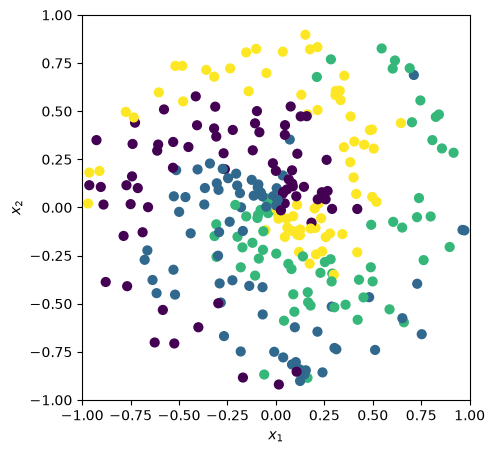

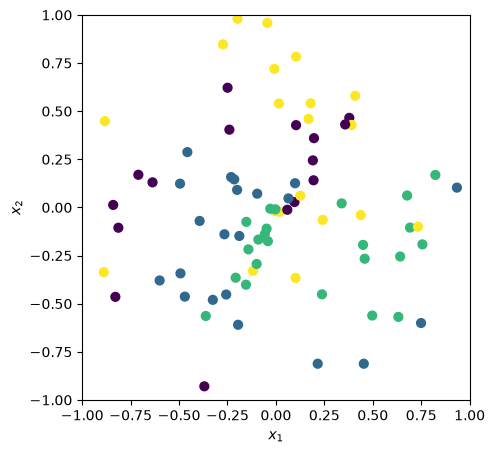

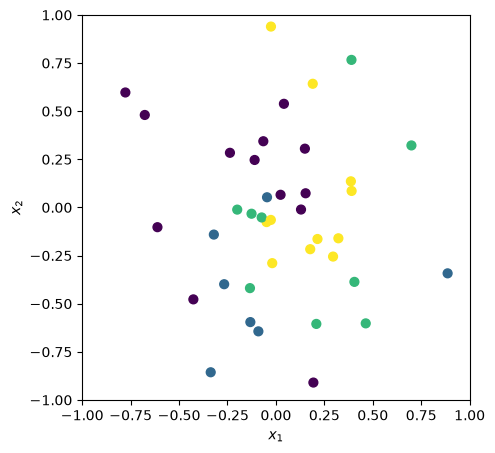

In [3]:
#################################################
#Edit to try different scenarios
#################################################
N = 100 # number of points per branch
K = 4  # number of branches
mag_noise = 0.7  # controls how much noise gets added to the data
dTheta    = 4    # difference in theta in each branch
#################################################

import matplotlib.pyplot as plt
import numpy as np

N_total = N * K # total number of points
X_all = np.zeros((N_total, 2)) # initialize matrix containing the 2-dimensional datapoints
y_all = np.zeros(N_total, dtype='uint8') # initialize labels, positive integer

### Data generation: ###
for j in range(K):
    ix = range(N*j, N*(j+1))
    r  = np.linspace(0.01, 1, N) # radius
    th = np.linspace(j*(2*np.pi)/K, j*(2*np.pi)/K + dTheta, N) + np.random.randn(N)*mag_noise
    X_all[ix] = np.c_[r*np.cos(th), r*np.sin(th)]
    y_all[ix] = j

### Shuffle and Split: ###
# Create a random permutation of indices to shuffle the sequential classes
indices = np.random.permutation(N_total)
X_shuffled = X_all[indices]
y_shuffled = y_all[indices]

# Calculate the index boundaries for the splits
train_end = int(0.7 * N_total)
test_end = train_end + int(0.2 * N_total)

# Slice the arrays into the 70/20/10 sets
x_train = X_shuffled[:train_end]
y_train = y_shuffled[:train_end]

x_test = X_shuffled[train_end:test_end]
y_test = y_shuffled[train_end:test_end]

x_final_test = X_shuffled[test_end:]
y_final_test = y_shuffled[test_end:]

# ==========================================
# 1. EXPORT THE DATA
# ==========================================
# Save all split arrays and K into the compressed file
np.savez_compressed(
    'spiral_data.npz',
    x_train=x_train, y_train=y_train,
    x_test=x_test, y_test=y_test,
    x_final_test=x_final_test, y_final_test=y_final_test,
    K=K
)

print(f"Data successfully exported to 'spiral_data.npz'")
print(f"Train set: {len(x_train)} points")
print(f"Test set: {len(x_test)} points")
print(f"Final test set: {len(x_final_test)} points")

### Plot the training data set: ###
fig = plt.figure(1, figsize=(5,5))
# Plotting just the training set to verify the spiral shape is intact
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=40)
plt.xlim([-1,1])
plt.ylim([-1,1])
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.savefig('spiral_data.pdf', bbox_inches="tight")
plt.show()

### Plot the test data set: ###
fig = plt.figure(1, figsize=(5,5))
plt.scatter(x_test[:, 0], x_test[:, 1], c=y_test, s=40)
plt.xlim([-1,1])
plt.ylim([-1,1])
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.savefig('spiral_data.pdf', bbox_inches="tight")
plt.show()

### Plot the verification data set: ###
fig = plt.figure(1, figsize=(5,5))
plt.scatter(x_final_test[:, 0], x_final_test[:, 1], c=y_final_test, s=40)
plt.xlim([-1,1])
plt.ylim([-1,1])
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.savefig('spiral_data.pdf', bbox_inches="tight")
plt.show()